# LOGISMART — Evidencias de modelado (H4–H5)

Este notebook **no entrena modelos**: muestra resultados obtenidos ejecutando `python main.py --proceso entrenar`. Los datos son sintéticos, no evidencia operativa real.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display

BASE = Path.cwd()
if BASE.name == "notebooks":
    BASE = BASE.parent
ruta = BASE / "models" / "resultados_modelado.json"
if not ruta.exists():
    raise FileNotFoundError("Ejecuta primero: python main.py --proceso entrenar")
resultados = json.loads(ruta.read_text(encoding="utf-8"))
print("Modelo elegido:", resultados["modelo_elegido"])
print("Modo rápido:", resultados["modo_rapido"])
print("Períodos:", resultados["periodos"])
print("Filas usadas:", resultados["filas_utilizadas"])

Modelo elegido: XGBoost
Modo rápido: False
Períodos: {'train': '2025-08 a 2026-06', 'validacion': '2026-07', 'test': '2026-08 a 2026-09'}
Filas usadas: {'train': 825299, 'validacion': 74766, 'test': 149935}


## Comparación en validación

La selección del modelo se basa en ROC-AUC de julio; PR-AUC desempata. **Test no interviene en la selección**.

In [2]:
tabla = pd.DataFrame(resultados["resultados_validacion_umbral_0_5"]).T
display(tabla.drop(columns=["matriz_confusion"]).round(4))

,roc_auc,pr_auc,precision,recall,f1,tasa_retraso_real,tasa_alertas,umbral
Random Forest,0.698365,0.28482,1.0,0.000097,0.000194,0.13767,0.000013,0.5
XGBoost,0.703692,0.289849,0.647436,0.009812,0.019332,0.13767,0.002087,0.5


## Evaluación final en test

Las métricas siguientes corresponden exclusivamente al modelo seleccionado y al umbral elegido con validación. No son resultados operativos reales.

In [3]:
r = resultados["resultado_test"]
display(pd.Series({k: v for k, v in r.items() if k != "matriz_confusion"}, name="Test").to_frame())
print("Matriz de confusión [TN, FP; FN, TP]:")
print(pd.DataFrame(r["matriz_confusion"], index=["Real 0", "Real 1"], columns=["Pred 0", "Pred 1"]))

,Test
roc_auc,0.707352
pr_auc,0.304437
precision,0.345559
recall,0.309521
f1,0.326548
tasa_retraso_real,0.145363
tasa_alertas,0.130203
umbral,0.150000


Matriz de confusión [TN, FP; FN, TP]:
        Pred 0  Pred 1
Real 0  115364   12776
Real 1   15049    6746


## Auditoría de umbrales y comunas

Genera los resultados con `python main.py --proceso evaluar`. Los gráficos de este notebook **no cambian parámetros ni reentrenan**.

In [4]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

base = Path.cwd()
if base.name == "notebooks":
    base = base.parent

modelos = base / "models"
def leer(nombre):
    ruta = modelos / nombre
    if not ruta.exists():
        raise FileNotFoundError(f"Falta {ruta}. Ejecuta python -m src.evaluacion desde la raíz.")
    return json.loads(ruta.read_text(encoding="utf-8"))

resumen = leer("resultados_modelado.json")
umbrales = pd.DataFrame(leer("auditoria_umbrales_validacion.json"))
comunas = pd.DataFrame(leer("auditoria_comunas_test.json"))
assert resumen["modo_rapido"] is False, "Ejecuta entrenamiento completo antes de documentar resultados oficiales"
print("Modelo:", resumen["modelo_elegido"], "| umbral oficial:", round(resumen["umbral_elegido_en_validacion"], 3))

Modelo: XGBoost | umbral oficial: 0.15


## 1. Umbrales de validación

Estos umbrales se comparan únicamente con **julio de 2026**. Las tasas de alerta permiten estimar carga operativa; no se usa test para seleccionar umbral.

,umbral,precision,recall,f1,tasa_alertas,tp,fp,fn,tn
0,0.05,0.1567,0.9424,0.2687,0.8279,9700,52196,593,12277
1,0.10,0.2152,0.7124,0.3306,0.4557,7333,26737,2960,37736
2,0.15,0.2616,0.5232,0.3488,0.2753,5385,15196,4908,49277
3,0.20,0.3107,0.3444,0.3267,0.1526,3545,7864,6748,56609
4,0.25,0.3624,0.2146,0.2696,0.0815,2209,3886,8084,60587
5,0.30,0.4131,0.1285,0.1961,0.0428,1323,1880,8970,62593
6,0.35,0.4791,0.0769,0.1326,0.0221,792,861,9501,63612
7,0.40,0.5306,0.0404,0.0751,0.0105,416,368,9877,64105
8,0.45,0.5734,0.0197,0.0381,0.0047,203,151,10090,64322
9,0.50,0.6474,0.0098,0.0193,0.0021,101,55,10192,64418


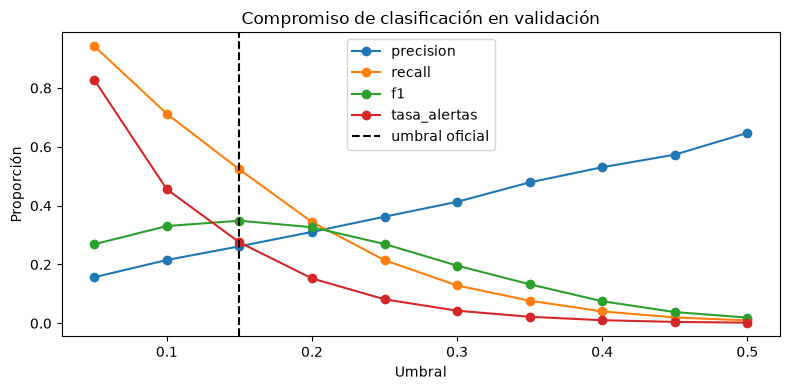

In [5]:
display(umbrales.round(4))
fig, ax = plt.subplots(figsize=(8,4))
for columna in ["precision", "recall", "f1", "tasa_alertas"]:
    ax.plot(umbrales["umbral"], umbrales[columna], marker="o", label=columna)
ax.axvline(resumen["umbral_elegido_en_validacion"], linestyle="--", color="black", label="umbral oficial")
ax.set(xlabel="Umbral", ylabel="Proporción", title="Compromiso de clasificación en validación")
ax.legend()
plt.tight_layout()
plt.show()

## 2. Desempeño territorial en test

La comparación por comunas es **descriptiva**, no determina cambios al modelo. El recall de comunas con pocos retrasos es más inestable.

,comuna_destino,operaciones,retrasos,tasa_retrasos,tasa_alertas,precision,recall,muestra_suficiente_recall
0,Santiago,22358,4173,0.1866,0.2159,0.3632,0.4201,True
1,Las Condes,15973,2679,0.1677,0.1815,0.3498,0.3785,True
2,Maipú,14270,2005,0.1405,0.1093,0.3314,0.2579,True
3,Providencia,12868,1981,0.1539,0.1467,0.3506,0.3342,True
4,La Florida,12700,1736,0.1367,0.1111,0.3381,0.2748,True
5,Puente Alto,11299,1706,0.1510,0.1514,0.3413,0.3423,True
6,Ñuñoa,11088,1339,0.1208,0.0767,0.3325,0.2114,True
7,Valparaíso,7924,1208,0.1524,0.1417,0.3411,0.3171,True
8,Quilicura,7911,901,0.1139,0.0630,0.2992,0.1654,True
9,Viña del Mar,7908,1128,0.1426,0.1155,0.3582,0.2899,True


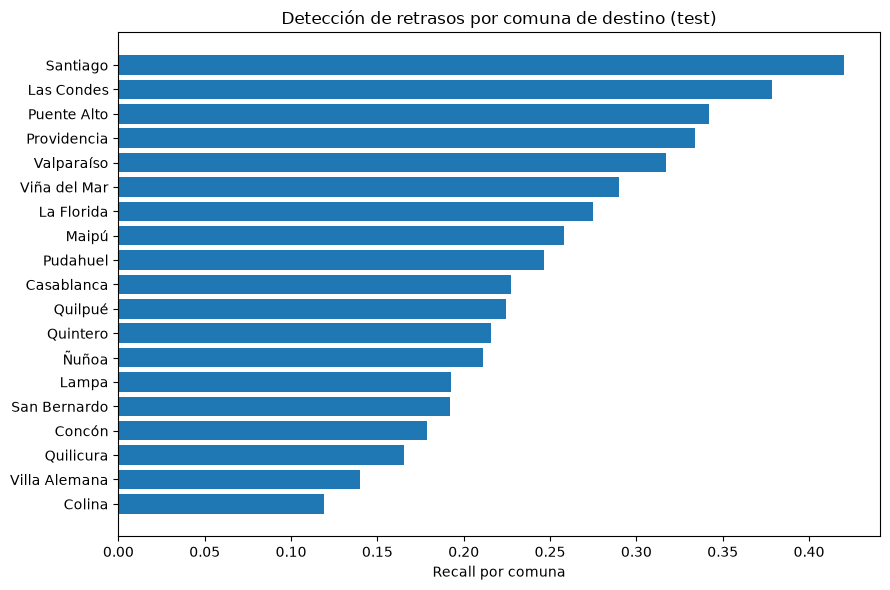

In [6]:
columnas = ["comuna_destino", "operaciones", "retrasos", "tasa_retrasos", "tasa_alertas", "precision", "recall", "muestra_suficiente_recall"]
display(comunas[columnas].round(4))
orden = comunas.sort_values("recall")
fig, ax = plt.subplots(figsize=(9,6))
ax.barh(orden["comuna_destino"], orden["recall"])
ax.set(xlabel="Recall por comuna", title="Detección de retrasos por comuna de destino (test)")
plt.tight_layout()
plt.show()

## 3. Interpretación y limitaciones

Documentar: ¿qué se gana o pierde con un umbral menor? ¿En qué comunas hay diferencias de recall? ¿Se deben a tasas base diferentes o a tamaños muestrales? No concluir impacto operativo a partir de datos sintéticos. La evaluación de test no autoriza reajustar parámetros usando esa misma muestra.